# W3 · From separate charts to a visual system
**Business Intelligence · IIB423T-1 · Individual workshop** — Benjamín Toloza Cossio · November 2026

**What this notebook is.** The editable source of the three views of my W3 document: one **before** and one **after** version
of each, drawn from the **same values**, plus the code of the visual system (colors, text styles, scales, labels, layout) that
all final views share.

**Data.** Results of the Group 06 C2 project (pre-race classifier of a top-10 finish, Formula 1 2014–2024; data: Kaggle
*Formula 1 World Championship (1950–2024)*, Ergast API). The three small CSV files next to this notebook were exported from the
C2 model run (validation folds 2018–2022, final test 2023–2024). The notebook only draws them; it trains nothing new.

**Files.** `w3_values_view1_f1_by_season.csv`, `w3_values_view2_test_outcomes.csv`, `w3_values_view3_disagreements.csv` →
figures in `figures/` (`V1_before.png`, `V1_after.png`, …).

## 1. Visual system (shared rules, written as code)
Every final view calls the same `STYLE`, `frame()` and `label_*` helpers, so a rule changes in one place for all three views.
The written version of these rules is section 2 of the document.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

os.makedirs("figures", exist_ok=True)

STYLE = {
    # color = which approach (categorical hue); orange = highlight of errors only
    "model": "#2A78D6", "reference": "#8A8984", "highlight": "#EB6834",
    "ink": "#16181C", "ink2": "#52514E", "grid": "#E6E6E3", "band": "#F2F1EE", "highlight_band": "#FDEEE7",
    # text styles (pt)
    "title": 13, "subtitle": 9.5, "group": 8.5, "axis": 9.5, "value": 9, "note": 8,
    # layout: one landscape frame for every final view
    "size": (8.2, 4.8), "top": 0.80, "bottom": 0.215,
}
MARKER = {"Model": dict(marker="o", ms=8, mfc=STYLE["model"], mec=STYLE["model"]),
          "Reference": dict(marker="D", ms=7, mfc="white", mec=STYLE["reference"], mew=1.8)}
SOURCE = "Source: Group 06 C2 project (Formula 1 2014–2024, Kaggle/Ergast). Positive class = finishes in the points (top 10)."

plt.rcParams.update({
    "font.family": "DejaVu Sans", "font.size": STYLE["axis"], "axes.edgecolor": "#BDBCB7", "axes.labelcolor": STYLE["ink2"],
    "xtick.color": STYLE["ink2"], "ytick.color": STYLE["ink"], "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": False, "figure.facecolor": "white", "axes.facecolor": "white"})

def frame(fig, title, subtitle, note, left):
    """Rule L1: title = the finding (top-left), subtitle = task + data scope, note = scale/method + source (bottom-left)."""
    fig.subplots_adjust(top=STYLE["top"], bottom=STYLE["bottom"], left=left, right=0.97)
    fig.text(0.012, 0.965, title, fontsize=STYLE["title"], fontweight="bold", color=STYLE["ink"], va="top")
    fig.text(0.012, 0.895, subtitle, fontsize=STYLE["subtitle"], color=STYLE["ink2"], va="top")
    fig.text(0.012, 0.015, note + "\n" + SOURCE, fontsize=STYLE["note"], color=STYLE["ink2"], va="bottom", linespacing=1.4)

def value_grid(ax, axis="x"):
    """Rule S3: light grid only along the value axis."""
    ax.grid(axis=axis, color=STYLE["grid"], lw=0.8); ax.set_axisbelow(True)

def save(fig, name):
    fig.savefig(f"figures/{name}.png", dpi=200); plt.show()
print("matplotlib", matplotlib.__version__, "| pandas", pd.__version__)

matplotlib 3.11.2 | pandas 3.0.5


## 2. Values (from the C2 project) and a cross-check
The asserts compare the CSV values with the numbers printed in the C2 notebook (`2_C2_model.ipynb`, parts 4–6). If a value
differed, the notebook would stop here.

In [2]:
v1 = pd.read_csv("w3_values_view1_f1_by_season.csv")
v2 = pd.read_csv("w3_values_view2_test_outcomes.csv").set_index("approach")
v3 = pd.read_csv("w3_values_view3_disagreements.csv")

assert np.allclose(v1.set_index("season").loc[[2018, 2019, 2020, 2021, 2022, 2023, 2024], "f1_model"].round(3),
                   [0.738, 0.723, 0.761, 0.794, 0.746, 0.798, 0.826])
assert np.allclose(v1.set_index("season").loc[[2018, 2019, 2020, 2021, 2022, 2023, 2024], "f1_reference"].round(3),
                   [0.743, 0.743, 0.747, 0.771, 0.731, 0.738, 0.838])
assert v2.loc["Model", ["TP", "FN", "FP", "TN"]].tolist() == [370, 90, 81, 378]
assert v2.loc["Reference", ["TP", "FN", "FP", "TN"]].tolist() == [363, 97, 96, 363]
g3 = v3.groupby(["group", "right"])["rows"].sum()
assert g3.sum() == 102 and g3[("Promoted: starts P11+", "Model right")] == 31 and g3[("Demoted: starts P1–P10", "Model right")] == 31
print("All values agree with the C2 results.")
display(v1.round(3), v2, g3.unstack())

All values agree with the C2 results.


,season,stage,period,races,f1_model,f1_reference
0,2018,validation,2014–2021 rules,21,0.738,0.743
1,2019,validation,2014–2021 rules,21,0.723,0.743
2,2020,validation,2014–2021 rules,17,0.761,0.747
3,2021,validation,2014–2021 rules,21,0.794,0.771
4,2022,validation,2022 rules,22,0.746,0.731
5,2023,test,2022 rules,22,0.798,0.738
6,2024,test,2022 rules,24,0.826,0.838


,TP,FN,FP,TN
approach,,,,
Model,370,90,81,378
Reference,363,97,96,363


right,Model right,Reference right
group,,
Demoted: starts P1–P10,31,24
Promoted: starts P11+,31,16


## 3. View 1 · Compare F1 of the model and the grid rule by season
**Before:** the C2 chart style (grouped bars on a truncated axis, legend box), redrawn with the same seven values.
**After:** dumbbell dot plot on a shared F1 position scale, seasons grouped by stage and regulation period, difference written
next to each pair.

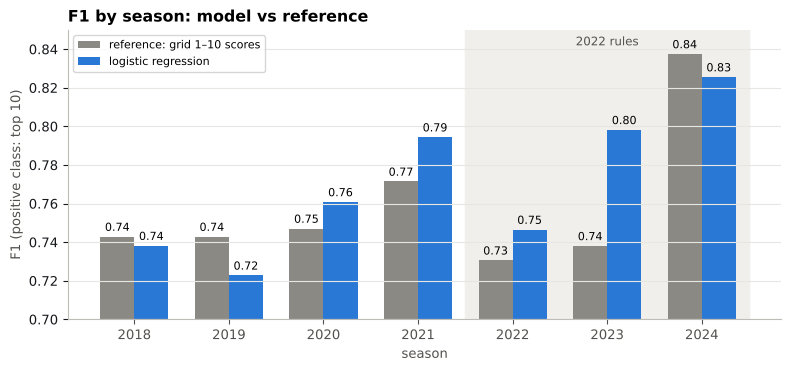

In [3]:
# BEFORE — C2 style: grouped bars, y-axis starting at 0.70, legend, two decimals
fig, ax = plt.subplots(figsize=(8, 3.8))
x = np.arange(len(v1))
ax.axvspan(3.5, 6.5, color="#f0efec", zorder=0); ax.text(5, 0.842, "2022 rules", ha="center", fontsize=8.5, color="#52514e")
ax.bar(x - 0.18, v1["f1_reference"], 0.36, color="#8a8984", label="reference: grid 1–10 scores")
ax.bar(x + 0.18, v1["f1_model"], 0.36, color="#2a78d6", label="logistic regression")
for i, (r, m) in enumerate(zip(v1["f1_reference"], v1["f1_model"])):
    ax.text(i - 0.18, r + 0.003, f"{r:.2f}", ha="center", fontsize=8); ax.text(i + 0.18, m + 0.003, f"{m:.2f}", ha="center", fontsize=8)
ax.set_xticks(x, v1["season"].astype(str)); ax.set_ylim(0.70, 0.85)
ax.set(xlabel="season", ylabel="F1 (positive class: top 10)"); ax.set_title("F1 by season: model vs reference", loc="left", fontweight="bold")
ax.legend(loc="upper left", fontsize=8); ax.grid(axis="y", color="#e6e6e3")
fig.tight_layout(); save(fig, "V1_before")

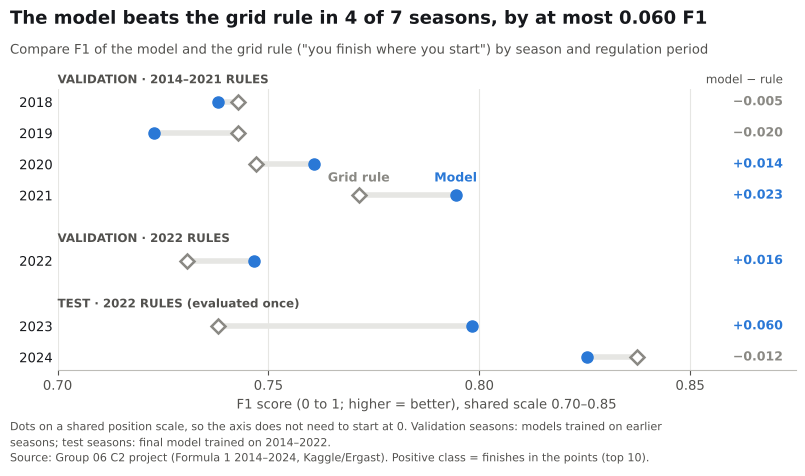

Seasons where the model is ahead: 4 of 7 | largest gap: 0.06


In [4]:
# AFTER — dumbbell dot plot, shared F1 scale, grouped rows, direct labels
order = [("VALIDATION · 2014–2021 RULES", [2018, 2019, 2020, 2021]), ("VALIDATION · 2022 RULES", [2022]),
         ("TEST · 2022 RULES (evaluated once)", [2023, 2024])]
rows, y, ypos, groups = v1.set_index("season"), 0, {}, []
for gname, seasons in order:
    groups.append((gname, y)); y += 0.75
    for s in seasons:
        ypos[s] = y; y += 1
    y += 0.35
fig, ax = plt.subplots(figsize=STYLE["size"])
for s, yy in ypos.items():
    m, r = rows.loc[s, "f1_model"], rows.loc[s, "f1_reference"]
    ax.plot([r, m], [yy, yy], color=STYLE["grid"], lw=4, solid_capstyle="round", zorder=1)
    ax.plot(r, yy, ls="none", zorder=3, **MARKER["Reference"]); ax.plot(m, yy, ls="none", zorder=4, **MARKER["Model"])
    d = m - r
    ax.text(0.872, yy, f"{d:+.3f}".replace("-", "\u2212"), va="center", ha="right", fontsize=STYLE["value"], fontweight="bold",
            color=STYLE["model"] if d > 0 else STYLE["reference"])
for gname, gy in groups:
    ax.text(0.700, gy + 0.05, gname, fontsize=STYLE["group"], color=STYLE["ink2"], fontweight="bold", va="center")
lab = ypos[2021]                                              # direct labels instead of a legend (rule L3)
ax.annotate("Model", (rows.loc[2021, "f1_model"], lab), xytext=(0, 10), textcoords="offset points", ha="center",
            fontsize=STYLE["value"], color=STYLE["model"], fontweight="bold")
ax.annotate("Grid rule", (rows.loc[2021, "f1_reference"], lab), xytext=(0, 10), textcoords="offset points", ha="center",
            fontsize=STYLE["value"], color=STYLE["reference"], fontweight="bold")
ax.text(0.872, groups[0][1] + 0.05, "model − rule", ha="right", va="center", fontsize=STYLE["group"], color=STYLE["ink2"])
ax.set_yticks(list(ypos.values()), [str(s) for s in ypos]); ax.invert_yaxis()
ax.set_xlim(0.70, 0.875); ax.set_xticks(np.arange(0.70, 0.851, 0.05))
ax.set_xlabel("F1 score (0 to 1; higher = better), shared scale 0.70–0.85")
ax.spines["left"].set_visible(False); ax.tick_params(axis="y", length=0); value_grid(ax)
frame(fig, "The model beats the grid rule in 4 of 7 seasons, by at most 0.060 F1",
      "Compare F1 of the model and the grid rule (\"you finish where you start\") by season and regulation period",
      "Dots on a shared position scale, so the axis does not need to start at 0. Validation seasons: models trained on earlier\n"
      "seasons; test seasons: final model trained on 2014–2022.", left=0.07)
save(fig, "V1_after")
print("Seasons where the model is ahead:", int((v1["f1_model"] > v1["f1_reference"]).sum()), "of", len(v1),
      "| largest gap:", round((v1["f1_model"] - v1["f1_reference"]).max(), 3))

## 4. View 2 · Compare the errors of the model and the grid rule on the test seasons
**Before:** the two C2 confusion-matrix heat maps (exact C2 code). **After:** one aligned bar chart of the four outcomes on a
common count scale starting at 0, errors first and highlighted.

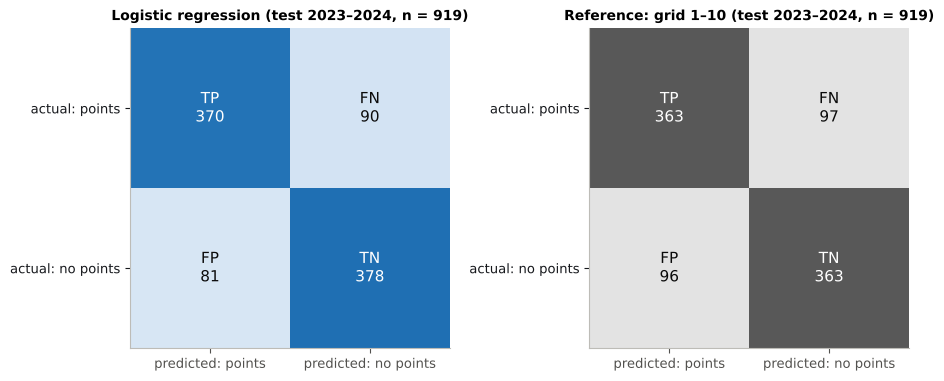

In [5]:
# BEFORE — C2 code: two heat maps with different color maps
fig, axes = plt.subplots(1, 2, figsize=(9.5, 3.9))
for ax, who, cmap in zip(axes, ["Model", "Reference"], ["Blues", "Greys"]):
    r = v2.loc[who]; cm = np.array([[r.TP, r.FN], [r.FP, r.TN]])
    ax.imshow(cm, cmap=cmap, vmin=0, vmax=500)
    lab = [["TP", "FN"], ["FP", "TN"]]
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{lab[i][j]}\n{cm[i, j]}", ha="center", va="center", fontsize=11, color="white" if cm[i, j] > 250 else "#0b0b0b")
    ax.set_xticks([0, 1], ["predicted: points", "predicted: no points"]); ax.set_yticks([0, 1], ["actual: points", "actual: no points"])
    ax.set_title(f"{'Logistic regression' if who == 'Model' else 'Reference: grid 1–10'} (test 2023–2024, n = 919)", fontsize=10, fontweight="bold")
fig.tight_layout(); save(fig, "V2_before")

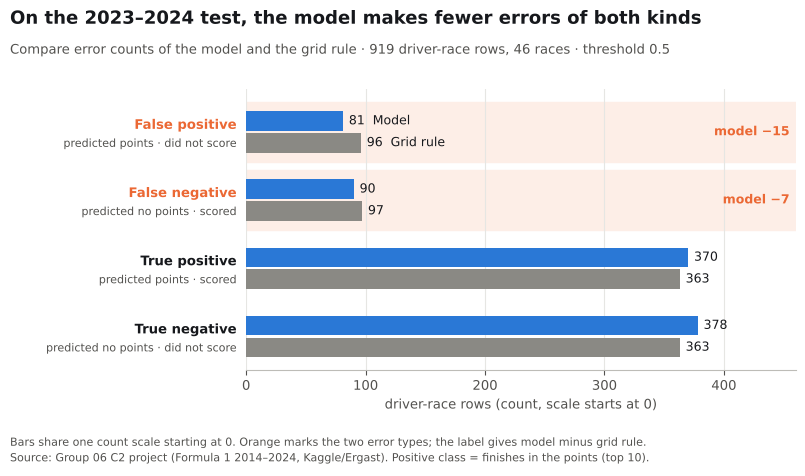

In [6]:
# AFTER — aligned horizontal bars, zero-based shared count scale, errors first and highlighted
outcomes = [("FP", "False positive", "predicted points · did not score", True),
            ("FN", "False negative", "predicted no points · scored", True),
            ("TP", "True positive", "predicted points · scored", False),
            ("TN", "True negative", "predicted no points · did not score", False)]
fig, ax = plt.subplots(figsize=STYLE["size"])
h, ticks = 0.36, []
for i, (k, name, desc, is_error) in enumerate(outcomes):
    yc = i * 1.25
    if is_error:
        ax.axhspan(yc - 0.55, yc + 0.55, color=STYLE["highlight_band"], zorder=0)
    for j, who in enumerate(["Model", "Reference"]):
        val = int(v2.loc[who, k]); yy = yc - h / 2 - 0.02 if who == "Model" else yc + h / 2 + 0.02
        ax.barh(yy, val, height=h, color=STYLE["model"] if who == "Model" else STYLE["reference"], zorder=2)
        ax.text(val + 5, yy, f"{val}" + (f"  {who if who == 'Model' else 'Grid rule'}" if i == 0 else ""), va="center",
                fontsize=STYLE["value"], color=STYLE["ink"])
    if is_error:
        diff = int(v2.loc["Model", k] - v2.loc["Reference", k])
        ax.text(455, yc, f"model {diff:+d}".replace("-", "\u2212"), va="center", ha="right", fontsize=STYLE["value"], fontweight="bold", color=STYLE["highlight"])
    ticks.append((yc, name, desc, is_error))
ax.set_yticks([t[0] for t in ticks], ["" for _ in ticks])
for yc, name, desc, is_error in ticks:
    ax.text(-8, yc - 0.12, name, ha="right", va="center", fontsize=STYLE["axis"], fontweight="bold",
            color=STYLE["highlight"] if is_error else STYLE["ink"])
    ax.text(-8, yc + 0.22, desc, ha="right", va="center", fontsize=STYLE["note"], color=STYLE["ink2"])
ax.invert_yaxis(); ax.set_xlim(0, 460); ax.set_xticks(range(0, 401, 100))
ax.set_xlabel("driver-race rows (count, scale starts at 0)")
ax.spines["left"].set_visible(False); ax.tick_params(axis="y", length=0); value_grid(ax)
frame(fig, "On the 2023–2024 test, the model makes fewer errors of both kinds",
      "Compare error counts of the model and the grid rule · 919 driver-race rows, 46 races · threshold 0.5",
      "Bars share one count scale starting at 0. Orange marks the two error types; the label gives model minus grid rule.", left=0.30)
save(fig, "V2_after")

## 5. View 3 · Identify where the model overrules the grid rule, and who was right
**Before:** slide 6 of the C2 presentation (text cards with big numbers), reproduced here with the same values.
**After:** one bar per type of disagreement on a common count scale, split into "model right" and "grid rule right".

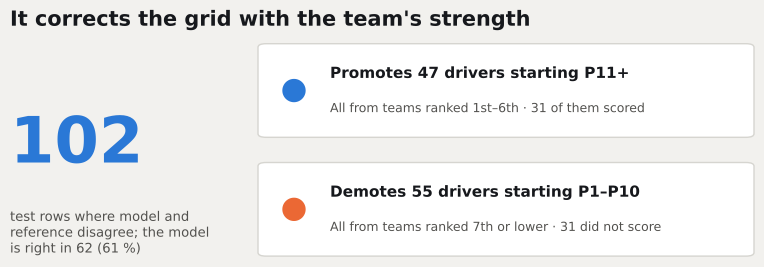

In [7]:
# BEFORE — reproduction of C2 slide 6 (text cards)
tot = g3.groupby(level=0).sum()
fig = plt.figure(figsize=(8, 3.6)); fig.patch.set_facecolor("#F2F1EE")
fig.text(0.04, 0.88, "It corrects the grid with the team's strength", fontsize=15, fontweight="bold", color="#16181C")
fig.text(0.04, 0.50, "102", fontsize=46, fontweight="bold", color="#2A78D6")
fig.text(0.04, 0.25, "test rows where model and\nreference disagree; the model\nis right in 62 (61 %)", fontsize=9.5, color="#52514E")
cards = [("Promotes 47 drivers starting P11+", "All from teams ranked 1st–6th · 31 of them scored", "#2A78D6"),
         ("Demotes 55 drivers starting P1–P10", "All from teams ranked 7th or lower · 31 did not score", "#EB6834")]
for i, (t, s, c) in enumerate(cards):
    yb = 0.58 - i * 0.33
    fig.patches.append(matplotlib.patches.FancyBboxPatch((0.36, yb), 0.6, 0.24, boxstyle="round,pad=0.01", transform=fig.transFigure,
                                                         facecolor="white", edgecolor="#D6D5D0"))
    fig.text(0.395, yb + 0.12, "\u25CF", fontsize=22, color=c, ha="center", va="center")
    fig.text(0.44, yb + 0.155, t, fontsize=11, fontweight="bold", color="#16181C")
    fig.text(0.44, yb + 0.06, s, fontsize=9, color="#52514E")
save(fig, "V3_before")

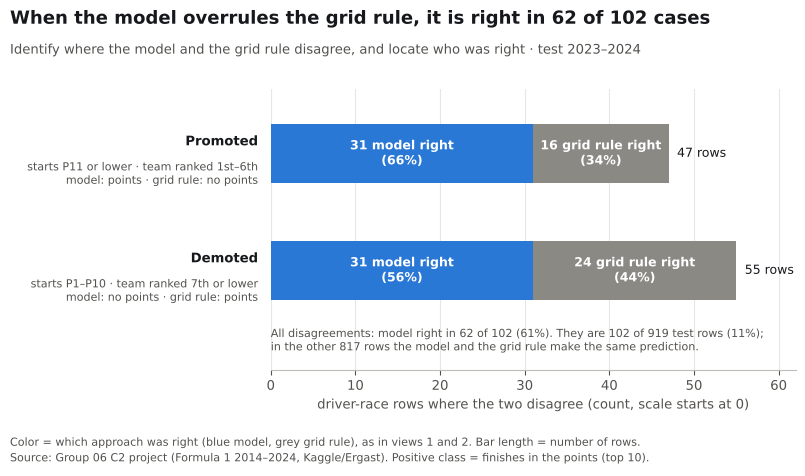

Breakdown by team tier (used in the limits section, not drawn in the final view):


right                             Model right  ...  model right share
group                  team_tier               ...                   
Demoted: starts P1–P10 7th+                31  ...               0.56
Promoted: starts P11+  4th–6th              5  ...               0.42
                       top 3               26  ...               0.74

[3 rows x 3 columns]

In [8]:
# AFTER — stacked horizontal bars on a shared count scale: model right (blue) | grid rule right (grey)
groups3 = [("Promoted: starts P11+", "Promoted", "starts P11 or lower · team ranked 1st–6th\nmodel: points · grid rule: no points"),
           ("Demoted: starts P1–P10", "Demoted", "starts P1–P10 · team ranked 7th or lower\nmodel: no points · grid rule: points")]
fig, ax = plt.subplots(figsize=STYLE["size"])
for i, (key, name, desc) in enumerate(groups3):
    mr, rr = int(g3[(key, "Model right")]), int(g3[(key, "Reference right")]); n = mr + rr
    ax.barh(i, mr, height=0.5, color=STYLE["model"], zorder=2)
    ax.barh(i, rr, left=mr, height=0.5, color=STYLE["reference"], zorder=2)
    ax.text(mr / 2, i, f"{mr} model right\n({mr / n:.0%})", ha="center", va="center", fontsize=STYLE["value"], color="white", fontweight="bold")
    ax.text(mr + rr / 2, i, f"{rr} grid rule right\n({rr / n:.0%})", ha="center", va="center", fontsize=STYLE["value"], color="white", fontweight="bold")
    ax.text(n + 1, i, f"{n} rows", va="center", fontsize=STYLE["value"], color=STYLE["ink"])
    ax.text(-1.5, i - 0.1, name, ha="right", va="center", fontsize=STYLE["axis"], fontweight="bold", color=STYLE["ink"])
    ax.text(-1.5, i + 0.17, desc, ha="right", va="center", fontsize=STYLE["note"], color=STYLE["ink2"], linespacing=1.3)
total_m = int(g3.xs("Model right", level=1).sum()); total = int(g3.sum())
ax.text(0, 1.6, f"All disagreements: model right in {total_m} of {total} ({total_m / total:.0%}). They are {total} of 919 test rows "
        f"({total / 919:.0%});\nin the other {919 - total} rows the model and the grid rule make the same prediction.",
        fontsize=STYLE["note"], color=STYLE["ink2"], va="center")
ax.set_yticks([0, 1], ["", ""]); ax.invert_yaxis(); ax.set_ylim(1.85, -0.55)
ax.set_xlim(0, 62); ax.set_xticks(range(0, 61, 10)); ax.set_xlabel("driver-race rows where the two disagree (count, scale starts at 0)")
ax.spines["left"].set_visible(False); ax.tick_params(axis="y", length=0); value_grid(ax)
frame(fig, f"When the model overrules the grid rule, it is right in {total_m} of {total} cases",
      "Identify where the model and the grid rule disagree, and locate who was right · test 2023–2024",
      "Color = which approach was right (blue model, grey grid rule), as in views 1 and 2. Bar length = number of rows.", left=0.33)
save(fig, "V3_after")
tier = v3.pivot_table(index=["group", "team_tier"], columns="right", values="rows", aggfunc="sum", fill_value=0)
tier["model right share"] = (tier["Model right"] / tier.sum(axis=1)).round(2)
print("Breakdown by team tier (used in the limits section, not drawn in the final view):")
tier

## 6. AI use
I used Claude (Anthropic, Cowork mode) to draft the plotting code and the first version of the written explanations, and to
check the views against the rubric. I checked every displayed value against the C2 notebook outputs (asserts in section 2),
reviewed each figure, and the design choices and their justification in the document are mine to defend.